In [ ]:
# Stores execution time of each CUDA kernel
results = {}

In [ ]:
%%writefile benchmark.cu

#include <cuda_runtime.h>
#include <stdio.h>

#define N 1000
#define BLOCK 32
#define ITERATIONS 20

#include "kernel1.cu"
#include "kernel2.cu"
#include "kernel3.cu"
#include "kernel4.cu"


float time_kernel_1(
    float* A,
    float* B,
    float* C,
    dim3 grid,
    dim3 block
) {
    for (int i = 0; i < 3; i++)
        naive_gemm<<<grid, block>>>(A, B, C);

    cudaDeviceSynchronize();

    cudaEvent_t start, stop;
    cudaEventCreate(&start);
    cudaEventCreate(&stop);

    cudaEventRecord(start);

    for (int i = 0; i < ITERATIONS; i++)
        naive_gemm<<<grid, block>>>(A, B, C);

    cudaEventRecord(stop);
    cudaEventSynchronize(stop);

    float ms;
    cudaEventElapsedTime(&ms, start, stop);

    cudaEventDestroy(start);
    cudaEventDestroy(stop);

    return ms / ITERATIONS;
}


float time_kernel_2(
    float* A,
    float* B,
    float* C,
    dim3 grid,
    dim3 block
) {
    for (int i = 0; i < 3; i++)
        coalesced_gemm<<<grid, block>>>(A, B, C);

    cudaDeviceSynchronize();

    cudaEvent_t start, stop;
    cudaEventCreate(&start);
    cudaEventCreate(&stop);

    cudaEventRecord(start);

    for (int i = 0; i < ITERATIONS; i++)
        coalesced_gemm<<<grid, block>>>(A, B, C);

    cudaEventRecord(stop);
    cudaEventSynchronize(stop);

    float ms;
    cudaEventElapsedTime(&ms, start, stop);

    cudaEventDestroy(start);
    cudaEventDestroy(stop);

    return ms / ITERATIONS;
}


float time_kernel_3(
    float* A,
    float* B,
    float* C,
    dim3 grid,
    dim3 block
) {
    for (int i = 0; i < 3; i++)
        smem_gemm<<<grid, block>>>(A, B, C);

    cudaDeviceSynchronize();

    cudaEvent_t start, stop;
    cudaEventCreate(&start);
    cudaEventCreate(&stop);

    cudaEventRecord(start);

    for (int i = 0; i < ITERATIONS; i++)
        smem_gemm<<<grid, block>>>(A, B, C);

    cudaEventRecord(stop);
    cudaEventSynchronize(stop);

    float ms;
    cudaEventElapsedTime(&ms, start, stop);

    cudaEventDestroy(start);
    cudaEventDestroy(stop);

    return ms / ITERATIONS;
}


float time_kernel_4(
    float* A,
    float* B,
    float* C
) {
    dim3 block(256);

    dim3 grid(
        (N + 128 - 1) / 128,
        (N + 128 - 1) / 128
    );

    for (int i = 0; i < 3; i++)
        optimized_gemm<<<grid, block>>>(A, B, C);

    cudaDeviceSynchronize();

    cudaEvent_t start, stop;
    cudaEventCreate(&start);
    cudaEventCreate(&stop);

    cudaEventRecord(start);

    for (int i = 0; i < ITERATIONS; i++)
        optimized_gemm<<<grid, block>>>(A, B, C);

    cudaEventRecord(stop);
    cudaEventSynchronize(stop);

    float ms;
    cudaEventElapsedTime(&ms, start, stop);

    cudaEventDestroy(start);
    cudaEventDestroy(stop);

    return ms / ITERATIONS;
}


int main()
{
    size_t bytes = N * N * sizeof(float);

    // -------------------------
    // Host memory
    // -------------------------

    float* h_A  = new float[N * N];
    float* h_B  = new float[N * N];

    for (int i = 0; i < N * N; i++) {
        h_A[i] = 1.0f;
        h_B[i] = 1.0f;
    }

    // -------------------------
    // Device memory
    // -------------------------

    float *d_A;
    float *d_B;
    float *d_C;

    cudaMalloc(&d_A, bytes);
    cudaMalloc(&d_B, bytes);
    cudaMalloc(&d_C, bytes);

    cudaMemcpy(
        d_A,
        h_A,
        bytes,
        cudaMemcpyHostToDevice
    );

    cudaMemcpy(
        d_B,
        h_B,
        bytes,
        cudaMemcpyHostToDevice
    );

    // -------------------------
    // Kernel 1-3 configuration
    // -------------------------

    dim3 block(BLOCK, BLOCK);

    dim3 grid(
        (N + BLOCK - 1) / BLOCK,
        (N + BLOCK - 1) / BLOCK
    );

    // -------------------------
    // Run all 4 kernels
    // -------------------------

    float t1 = time_kernel_1(
        d_A,
        d_B,
        d_C,
        grid,
        block
    );

    float t2 = time_kernel_2(
        d_A,
        d_B,
        d_C,
        grid,
        block
    );

    float t3 = time_kernel_3(
        d_A,
        d_B,
        d_C,
        grid,
        block
    );

    float t4 = time_kernel_4(
        d_A,
        d_B,
        d_C
    );

    // -------------------------
    // Print results
    // -------------------------

    printf("Naive %.6f\n", t1);
    printf("Coalesced %.6f\n", t2);
    printf("SMEM_Tiling %.6f\n", t3);
    printf("Fully_Optimized %.6f\n", t4);

    // -------------------------
    // Cleanup
    // -------------------------

    cudaFree(d_A);
    cudaFree(d_B);
    cudaFree(d_C);

    delete[] h_A;
    delete[] h_B;

    return 0;
}

Overwriting benchmark.cu


In [ ]:
%%writefile kernel1.cu

#define N 1000

__global__ void naive_gemm(
    const float* A,
    const float* B,
    float* C
) {
    int row = blockIdx.x * blockDim.x + threadIdx.x;
    int col = blockIdx.y * blockDim.y + threadIdx.y;

    if (row < N && col < N) {

        float sum = 0.0f;

        for (int k = 0; k < N; k++) {
            sum += A[row * N + k] * B[k * N + col];
        }

        C[row * N + col] = sum;
    }
}

Writing kernel1.cu


In [ ]:
%%writefile kernel2.cu

#define N 1000

__global__ void coalesced_gemm(
    const float* A,
    const float* B,
    float* C
) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;

    if (row < N && col < N) {

        float sum = 0.0f;

        for (int k = 0; k < N; k++) {
            sum += A[row * N + k] * B[k * N + col];
        }

        C[row * N + col] = sum;
    }
}

Writing kernel2.cu


In [ ]:
%%writefile kernel3.cu

#define N 1000
#define TILE 32

__global__ void smem_gemm(const float* A, const float* B, float* C)
{
    __shared__ float As[TILE][TILE];
    __shared__ float Bs[TILE][TILE];

    int row = blockIdx.y * TILE + threadIdx.y;
    int col = blockIdx.x * TILE + threadIdx.x;

    float sum = 0.0f;

    for (int t = 0; t < N; t += TILE)
    {
        if (row < N && t + threadIdx.x < N)
            As[threadIdx.y][threadIdx.x] =
                A[row * N + t + threadIdx.x];
        else
            As[threadIdx.y][threadIdx.x] = 0.0f;

        if (t + threadIdx.y < N && col < N)
            Bs[threadIdx.y][threadIdx.x] =
                B[(t + threadIdx.y) * N + col];
        else
            Bs[threadIdx.y][threadIdx.x] = 0.0f;

        __syncthreads();

        for (int k = 0; k < TILE; k++)
            sum += As[threadIdx.y][k] * Bs[k][threadIdx.x];

        __syncthreads();
    }

    if (row < N && col < N)
        C[row * N + col] = sum;
}

Writing kernel3.cu


In [ ]:
%%writefile kernel4.cu

#define N 1000

#define BM 128
#define BN 128
#define BK 8

#define TM 8
#define TN 8

#define THREADS 256

__global__ void optimized_gemm(
    const float* A,
    const float* B,
    float* C
) {
    __shared__ float As[BM][BK];
    __shared__ float Bs[BK][BN];

    int tid = threadIdx.x;

    // 8 warps per block
    int warp_id = tid / 32;
    int lane    = tid % 32;

    // 2 warps across, 4 warps down
    int warp_row = warp_id / 2;
    int warp_col = warp_id % 2;

    // Each warp = 32 x 64
    // Each thread = 8 x 8
    int lane_row = lane / 8;
    int lane_col = lane % 8;

    int row_start = warp_row * 32 + lane_row * TM;
    int col_start = warp_col * 64 + lane_col * TN;

    float acc[TM][TN] = {0.0f};

    for (int bk = 0; bk < N; bk += BK) {

        // Load A tile
        for (int i = tid; i < BM * BK; i += THREADS) {

            int r = i / BK;
            int c = i % BK;

            int gr = blockIdx.y * BM + r;
            int gc = bk + c;

            As[r][c] =
                (gr < N && gc < N)
                ? A[gr * N + gc]
                : 0.0f;
        }

        // Load B tile
        for (int i = tid; i < BK * BN; i += THREADS) {

            int r = i / BN;
            int c = i % BN;

            int gr = bk + r;
            int gc = blockIdx.x * BN + c;

            Bs[r][c] =
                (gr < N && gc < N)
                ? B[gr * N + gc]
                : 0.0f;
        }

        __syncthreads();

        // Compute 8 x 8 register tile
        #pragma unroll
        for (int k = 0; k < BK; k++) {

            float a[TM];
            float b[TN];

            #pragma unroll
            for (int i = 0; i < TM; i++)
                a[i] = As[row_start + i][k];

            #pragma unroll
            for (int j = 0; j < TN; j++)
                b[j] = Bs[k][col_start + j];

            #pragma unroll
            for (int i = 0; i < TM; i++)
                #pragma unroll
                for (int j = 0; j < TN; j++)
                    acc[i][j] += a[i] * b[j];
        }

        __syncthreads();
    }

    // Store 8 x 8 register tile
    int row = blockIdx.y * BM + row_start;
    int col = blockIdx.x * BN + col_start;

    #pragma unroll
    for (int i = 0; i < TM; i++) {

        #pragma unroll
        for (int j = 0; j < TN; j++) {

            if (row + i < N && col + j < N)
                C[(row + i) * N + (col + j)] = acc[i][j];
        }
    }
}

Overwriting kernel4.cu


In [ ]:
!ls -l benchmark.cu
!nvcc -O3 benchmark.cu -o benchmark
!./benchmark

-rw-r--r-- 1 root root 4607 Aug 16 22:32 benchmark.cu
nvcc warning : Support for offline compilation for architectures prior to '<compute/sm/lto>_75' will be removed in a future release (Use -Wno-deprecated-gpu-targets to suppress warning).
Naive 20.179455
Coalesced 2.560811
SMEM_Tiling 2.306150
Fully_Optimized 0.857931


In [ ]:
import subprocess

output = subprocess.check_output(["./benchmark"]).decode()

results = {}

for line in output.strip().splitlines():
    name, time = line.split()
    results[name] = float(time)

print(results)

{'Naive': 21.523682, 'Coalesced': 2.638363, 'SMEM_Tiling': 2.42505, 'Fully_Optimized': 0.84737}


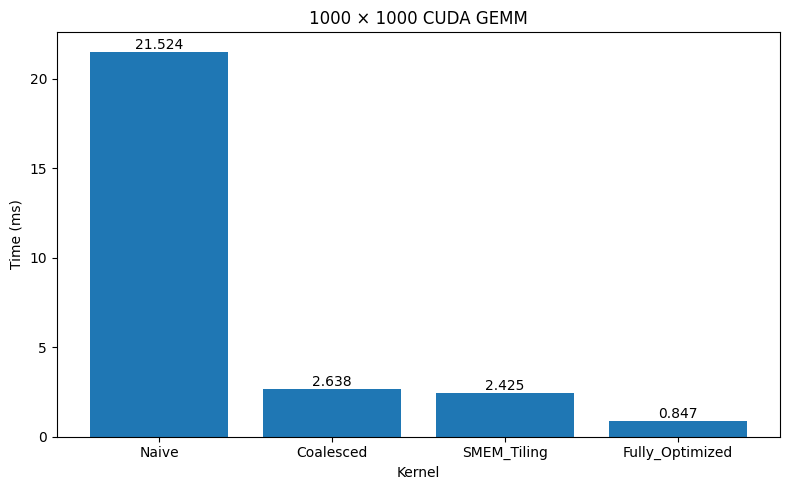

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

bars = plt.bar(results.keys(), results.values())

plt.xlabel("Kernel")
plt.ylabel("Time (ms)")
plt.title("1000 × 1000 CUDA GEMM")

for bar, value in zip(bars, results.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()